# Online Shopping Purchase Prediction

Predict whether an online shopping session ends in a purchase (`Revenue`). This notebook follows the same workflow as Challenge 1: explore the data, prepare features and validation, compare models, tune selected candidates, select the final model, and generate predictions. `ID` is retained only for the final submission.

## Imports and reproducibility

In [1]:
# 1. Import packages
from IPython.display import display
from pathlib import Path

# Core data handling
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Preprocessing + pipelines
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Validation tools and classification metrics
from sklearn.metrics import (average_precision_score, classification_report,
                             confusion_matrix, f1_score, make_scorer,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV

# Reproducibility: every random process uses this seed
RANDOM_STATE = 42
N_SPLITS = 5
PROJECT_ROOT = (Path(__file__).resolve().parents[1] if '__file__' in globals()
                else Path.cwd().parent if Path.cwd().name == 'models' else Path.cwd())

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)

## Task 1 — Explore and prepare the data

In [2]:
# 2. Load and inspect
df_train = pd.read_csv(PROJECT_ROOT / 'data' / 'challenge2_train.csv')
df_test = pd.read_csv(PROJECT_ROOT / 'data' / 'challenge2_test.csv')  # final predictions only

TARGET = 'Revenue'
ID_COLUMN = 'ID'

print('Train shape:', df_train.shape, '| Test shape:', df_test.shape)
display(df_train.head())
df_train.info()

# Confirm the two files can use the same feature preparation.
train_predictors = set(df_train.columns) - {TARGET}
test_predictors = set(df_test.columns)
assert train_predictors == test_predictors, 'Train and test predictors must match.'
assert df_train[ID_COLUMN].is_unique and df_test[ID_COLUMN].is_unique, 'IDs must be unique.'
print('Predictor schemas match:', train_predictors == test_predictors)
print('Missing values (train):', df_train.isna().sum().sum())
print('Missing values (test): ', df_test.isna().sum().sum())
print('Duplicate rows (train):', df_train.duplicated().sum())
print('Duplicate rows (test): ', df_test.duplicated().sum())

# Numeric summary, excluding ID because it is an identifier rather than a predictor.
display(df_train.drop(columns=[ID_COLUMN, TARGET]).describe().T)

Train shape: (9247, 19) | Test shape: (3083, 18)


,ID,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,1,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,3,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
2,4,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
3,7,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
4,9,0,0.0,0,0.0,2,37.000000,0.00,0.10,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False,False


<class 'pandas.DataFrame'>
RangeIndex: 9247 entries, 0 to 9246
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       9247 non-null   int64  
 1   Administrative           9247 non-null   int64  
 2   Administrative_Duration  9247 non-null   float64
 3   Informational            9247 non-null   int64  
 4   Informational_Duration   9247 non-null   float64
 5   ProductRelated           9247 non-null   int64  
 6   ProductRelated_Duration  9247 non-null   float64
 7   BounceRates              9247 non-null   float64
 8   ExitRates                9247 non-null   float64
 9   PageValues               9247 non-null   float64
 10  SpecialDay               9247 non-null   float64
 11  Month                    9247 non-null   str    
 12  OperatingSystems         9247 non-null   int64  
 13  Browser                  9247 non-null   int64  
 14  Region                   9247 non-n

,count,mean,std,min,25%,50%,75%,max
Administrative,9247.0,2.314372,3.319935,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,9247.0,81.168776,179.593423,0.0,0.000000,8.000000,92.550000,3398.750000
Informational,9247.0,0.502433,1.272332,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,9247.0,34.517405,141.310276,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,9247.0,31.358170,43.539969,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,9247.0,1181.847920,1908.101262,0.0,181.416667,598.250000,1464.986002,63973.522230
BounceRates,9247.0,0.022268,0.048680,0.0,0.000000,0.003030,0.016834,0.200000
ExitRates,9247.0,0.043231,0.048835,0.0,0.014286,0.025088,0.050000,0.200000
PageValues,9247.0,5.983551,18.753351,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,9247.0,0.063307,0.201943,0.0,0.000000,0.000000,0.000000,1.000000


,count,share
Revenue,,
False,7816,0.845247
True,1431,0.154753


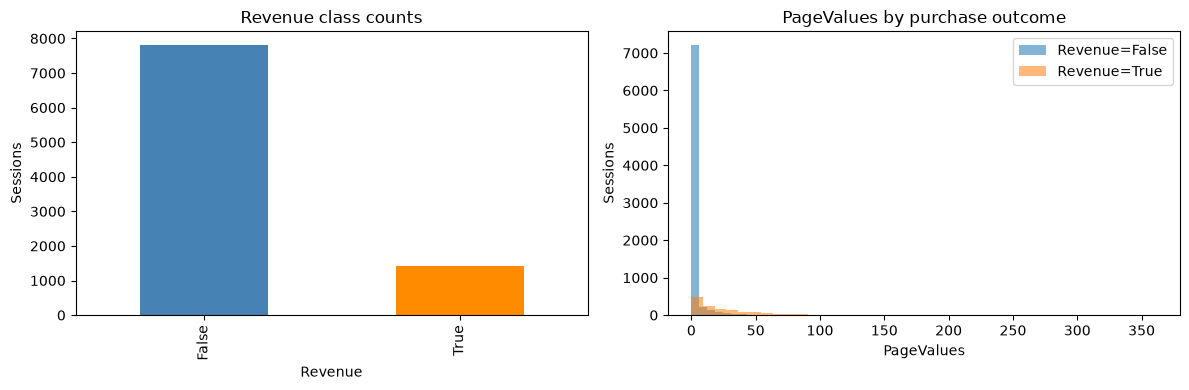

Month: 10 train levels; unseen test levels: []
OperatingSystems: 8 train levels; unseen test levels: []
Browser: 13 train levels; unseen test levels: []
Region: 9 train levels; unseen test levels: []
TrafficType: 20 train levels; unseen test levels: []
VisitorType: 3 train levels; unseen test levels: []
Weekend: 2 train levels; unseen test levels: []


In [3]:
# The positive class is uncommon, so accuracy alone would be misleading.
class_counts = df_train[TARGET].value_counts().rename_axis(TARGET).to_frame('count')
class_counts['share'] = class_counts['count'] / len(df_train)
display(class_counts)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_counts['count'].plot(kind='bar', ax=axes[0], color=['steelblue', 'darkorange'])
axes[0].set_title('Revenue class counts')
axes[0].set_xlabel('Revenue'); axes[0].set_ylabel('Sessions')

for label, group in df_train.groupby(TARGET):
    axes[1].hist(group['PageValues'], bins=40, alpha=0.55, label=f'Revenue={label}')
axes[1].set_title('PageValues by purchase outcome')
axes[1].set_xlabel('PageValues'); axes[1].set_ylabel('Sessions')
axes[1].legend()
plt.tight_layout()
plt.show()

# Check categorical levels and ensure the test set has no unseen values.
categorical_columns = ['Month', 'OperatingSystems', 'Browser', 'Region',
                       'TrafficType', 'VisitorType', 'Weekend']
for col in categorical_columns:
    unseen = set(df_test[col].dropna()) - set(df_train[col].dropna())
    print(f'{col}: {df_train[col].nunique()} train levels; unseen test levels: {sorted(unseen)}')

### Feature preparation

`Month`, visitor/device/browser/region/traffic codes, and `Weekend` are categorical. Counts, durations, rates, `PageValues`, and `SpecialDay` remain numeric. We exclude `ID`; its numeric ordering carries no session behavior. Even though this dataset has no missing values, imputation is included inside the pipeline so it is learned separately within each validation fold and the workflow remains robust. Numeric features are scaled for distance- and margin-based models; categorical features are one-hot encoded with unknown-level handling for the final test set.

In [4]:
# 3. Prepare predictors and preprocessing. ID is never a model feature.
X = df_train.drop(columns=[ID_COLUMN, TARGET])
y = df_train[TARGET].astype(bool)
X_test = df_test.drop(columns=ID_COLUMN)

numeric_columns = [col for col in X.columns if col not in categorical_columns]
print('Categorical columns:', categorical_columns)
print('Numeric columns:', numeric_columns)

categorical_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
numeric_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])
preprocessor = ColumnTransformer(transformers=[
    ('categorical', categorical_pipeline, categorical_columns),
    ('numeric', numeric_pipeline, numeric_columns),
])

Categorical columns: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
Numeric columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']


## Task 2 — Validation strategy

We use shuffled, stratified five-fold cross-validation with `random_state=42`. Stratification preserves the roughly 15% purchase rate in every validation fold, which makes the rare positive class available for each F1 calculation. All baseline models and Grid Search candidates must use these same folds. The primary metric is F1 for `Revenue=True`, which balances precision and recall. Precision, recall, ROC AUC, average precision, train-versus-validation F1, and an out-of-fold confusion matrix provide context. A final result chosen using these same folds can be somewhat optimistic; record that limitation when selecting the model.

In [5]:
# 4. Shared validation configuration for every model and Grid Search
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'f1': make_scorer(f1_score, pos_label=True, zero_division=0),
    'precision': make_scorer(precision_score, pos_label=True, zero_division=0),
    'recall': make_scorer(recall_score, pos_label=True, zero_division=0),
    'roc_auc': 'roc_auc',
    'average_precision': 'average_precision',
}

# Verify that every fold retains the class balance before modeling.
fold_summary = []
for fold, (train_idx, valid_idx) in enumerate(cv.split(X, y), start=1):
    fold_summary.append({
        'fold': fold,
        'train_rows': len(train_idx),
        'validation_rows': len(valid_idx),
        'train_positive_rate': y.iloc[train_idx].mean(),
        'validation_positive_rate': y.iloc[valid_idx].mean(),
    })
display(pd.DataFrame(fold_summary).round(4))

print('Primary metric: F1 score for Revenue=True')
print('Supporting metrics: precision, recall, ROC AUC, average precision, and confusion matrix')

,fold,train_rows,validation_rows,train_positive_rate,validation_positive_rate
0,1,7397,1850,0.1548,0.1546
1,2,7397,1850,0.1547,0.1551
2,3,7398,1849,0.1548,0.1547
3,4,7398,1849,0.1548,0.1547
4,5,7398,1849,0.1548,0.1547


Primary metric: F1 score for Revenue=True
Supporting metrics: precision, recall, ROC AUC, average precision, and confusion matrix


## Next steps

Tasks 3–6 will add the seven required classifiers, a comparison table, Grid Search for selected models, final-model rationale, and `submissions/predictions.csv`.